# Scratch-MLP: Understanding Backpropagation from First Principles

This notebook outlines the design and structure for building a Multi-Layer Perceptron (MLP) from scratch using only **NumPy**. The goal is to solidify our understanding of feedforward networks, activation functions, loss calculations, and, most importantly, the mathematical mechanics of backpropagation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
from pathlib import Path

## MNIST Dataset Preparation

We use **NumPy** to load the original MNIST dataset from `mnist.npz`, which contains:
- `x_train`: 60,000 training images (28 × 28 pixels)
- `y_train`: 60,000 training labels
- `x_test`: 10,000 test images (28 × 28 pixels)
- `y_test`: 10,000 test labels

The dataset is cached locally to avoid repeated downloads.

In [2]:
DATA_PATH = Path("mnist.npz")
URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"

# Download only if the file doesn't exist
if not DATA_PATH.exists():
    print("Downloading MNIST...")
    urllib.request.urlretrieve(URL, DATA_PATH)
else:
    print("MNIST already exists. Skipping download.")

# Load dataset
with np.load(DATA_PATH) as data:
    X_train = data["x_train"].reshape(-1, 784).astype(np.float32) / 255.0
    y_train = data["y_train"]

    X_test = data["x_test"].reshape(-1, 784).astype(np.float32) / 255.0
    y_test = data["y_test"]

print("Dataset loaded successfully!")

MNIST already exists. Skipping download.
Dataset loaded successfully!


## Mathematical Components

Our MLP is built from reusable mathematical components, each implementing its own forward and backward propagation operations.

### Linear Layer (Fully Connected)

**Forward propagation (single sample):**

$$
z = Wx + b
$$

Where:
- $x \in \mathbb{R}^{d_{in}}$: Input vector
- $W \in \mathbb{R}^{d_{out} \times d_{in}}$: Weight matrix
- $b \in \mathbb{R}^{d_{out}}$: Bias vector
- $z \in \mathbb{R}^{d_{out}}$: Output before activation

**Backward propagation (single sample):**

$$
\frac{\partial \mathcal{L}}{\partial W}
= \frac{\partial \mathcal{L}}{\partial z}x^T
$$

$$
\frac{\partial \mathcal{L}}{\partial b}
= \frac{\partial \mathcal{L}}{\partial z}
$$

$$
\frac{\partial \mathcal{L}}{\partial x}
= W^T\frac{\partial \mathcal{L}}{\partial z}
$$

### Mini-Batch Computation

For efficient training, we process $N$ samples simultaneously, arranging each input vector as a row of the input matrix.

**Forward propagation:**

$$
Z = XW^T + \mathbf{1}_N b^T
$$

Where:
- $X \in \mathbb{R}^{N \times d_{in}}$: Input batch
- $W \in \mathbb{R}^{d_{out} \times d_{in}}$: Weight matrix
- $b \in \mathbb{R}^{d_{out} \times 1}$: Bias vector
- $\mathbf{1}_N \in \mathbb{R}^{N \times 1}$: Vector of ones
- $Z \in \mathbb{R}^{N \times d_{out}}$: Output before activation

**Backward propagation:**

Let

$$
G = \frac{\partial \mathcal{L}}{\partial Z}
\in \mathbb{R}^{N \times d_{out}}
$$

Then:

$$
\frac{\partial \mathcal{L}}{\partial W}
= G^T X
$$

$$
\frac{\partial \mathcal{L}}{\partial b}
= G^T\mathbf{1}_N
$$

$$
\frac{\partial \mathcal{L}}{\partial X}
= GW
$$

In [3]:
class Linear:
    def __init__(self, n_in, n_out, rng, dtype=np.float32):
        self.dtype = np.dtype(dtype)

        self.W = rng.normal(
            0, np.sqrt(2 / n_in), (n_out, n_in)
        ).astype(self.dtype)

        self.b = np.zeros((n_out, 1), dtype=self.dtype)

    def forward(self, X):
        self.X = np.asarray(X, dtype=self.dtype)
        return self.X @ self.W.T + self.b.T

    def backward(self, dZ):
        dZ = np.asarray(dZ, dtype=self.dtype)

        self.dW = dZ.T @ self.X
        self.db = dZ.sum(axis=0, keepdims=True).T

        return dZ @ self.W

    def step(self, lr):
        self.W -= lr * self.dW
        self.b -= lr * self.db

### ReLU (Hidden Layers)

**Forward propagation:**

$$
A = f(Z) = \max(0,Z)
$$

Where:
- $Z \in \mathbb{R}^{N \times d_{out}}$: Input before activation
- $A \in \mathbb{R}^{N \times d_{out}}$: Output after activation
- $f$: ReLU function applied element-wise

**Derivative:**

$$
f'(z) =
\begin{cases}
1, & z > 0 \\
0, & z \leq 0
\end{cases}
$$

**Backward propagation:**

$$
\frac{\partial \mathcal{L}}{\partial Z}
=
\frac{\partial \mathcal{L}}{\partial A}
\odot f'(Z)
$$

where $\odot$ represents element-wise multiplication.

In [4]:
class ReLU:
    def forward(self, X):
        self.X = X
        return np.maximum(0, X)

    def backward(self, dA):
        return dA * (self.X > 0)

### Softmax (Output Probabilities)

For $C$ output classes:

$$
P_{i,c} =
\frac{e^{Z_{i,c}}}
{\sum_{j=1}^{C}e^{Z_{i,j}}}
$$

Where $P_{i,c}$ represents the predicted probability that sample $i$ belongs to class $c$.

For numerical stability, we subtract the maximum logit before exponentiation:

$$
P_{i,c} =
\frac{e^{Z_{i,c}-m_i}}
{\sum_{j=1}^{C}e^{Z_{i,j}-m_i}},
\qquad
m_i = \max_j Z_{i,j}
$$

### Loss Function — Categorical Cross-Entropy

For multi-class classification (MNIST digit recognition), we use categorical cross-entropy:

$$
\mathcal{L}
=
-\frac{1}{N}
\sum_{i=1}^{N}
\sum_{c=1}^{C}
Y_{i,c}\log(P_{i,c})
$$

Where:
- $N$: Number of samples in a mini-batch
- $C$: Number of classes (10 for MNIST)
- $Y_{i,c}$: One-hot encoded ground-truth label
- $P_{i,c}$: Predicted probability for class $c$

Since our implementation stores labels as integer class indices $y_i \in \{0,\ldots,9\}$ rather than one-hot vectors, we calculate the equivalent loss as:

$$
\boxed{
\mathcal{L}
=
-\frac{1}{N}
\sum_{i=1}^{N}\log(P_{i,y_i})
}
$$

Our `SoftmaxCrossEntropy` class combines softmax and cross-entropy into a single component.

**Backward propagation (Softmax + Cross-Entropy):**

The combined derivative with respect to the output logits simplifies to:

$$
\boxed{
\frac{\partial \mathcal{L}}{\partial Z}
=
\frac{P-Y}{N}
}
$$

In [5]:
class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        self.y = y
        N = len(y)

        shifted = logits - logits.max(
            axis=1, keepdims=True
        )

        log_probs = shifted - np.log(
            np.exp(shifted).sum(axis=1, keepdims=True)
        )

        self.probs = np.exp(log_probs)

        return -log_probs[np.arange(N), y].mean()

    def backward(self):
        N = len(self.y)

        dZ = self.probs.copy()
        dZ[np.arange(N), self.y] -= 1

        return dZ / N

### Gradient Descent (Parameter Updates)

After backpropagation computes the gradients, we update each trainable parameter using mini-batch stochastic gradient descent (SGD):

$$
W \leftarrow W-\alpha\frac{\partial \mathcal{L}}{\partial W}
$$

$$
b \leftarrow b-\alpha\frac{\partial \mathcal{L}}{\partial b}
$$

Where $\alpha$ is the learning rate.

The process is repeated across mini-batches until training reaches its stopping criterion.

The MLP below composes `Linear`, `ReLU`, and `SoftmaxCrossEntropy` layers rather than reimplementing their gradients.

In [6]:
class MLP:
    def __init__(self, sizes, learning_rate=0.1,
                 seed=42, dtype=np.float32):
        """
        sizes = [784, 128, 64, 10], for example.
        """
        if len(sizes) < 2 or any(n <= 0 for n in sizes):
            raise ValueError("Specify at least input and output sizes.")

        self.sizes = list(sizes)
        self.lr = learning_rate
        self.dtype = np.dtype(dtype)
        self.rng = np.random.default_rng(seed)

        self.layers = []
        self.loss_history = []

        for i in range(len(sizes) - 1):
            self.layers.append(
                Linear(
                    sizes[i],
                    sizes[i + 1],
                    self.rng,
                    dtype=self.dtype
                )
            )

            if i < len(sizes) - 2:
                self.layers.append(ReLU())

        self.criterion = SoftmaxCrossEntropy()

    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def backward(self):
        grad = self.criterion.backward()

        for layer in reversed(self.layers):
            grad = layer.backward(grad)

    def step(self):
        for layer in self.layers:
            if isinstance(layer, Linear):
                layer.step(self.lr)

    def train_batch(self, X, y):
        logits = self.forward(X)

        loss = self.criterion.forward(logits, y)

        self.backward()
        self.step()

        return float(loss)

    def train(self, X, y, epochs=20, batch_size=128):
        X = np.asarray(X, dtype=self.dtype)
        y = np.asarray(y)

        n = len(X)

        for epoch in range(epochs):
            indices = self.rng.permutation(n)

            total_loss = 0.0

            for start in range(0, n, batch_size):
                idx = indices[start:start + batch_size]

                X_batch = X[idx]
                y_batch = y[idx]

                loss = self.train_batch(X_batch, y_batch)

                total_loss += loss * len(idx)

            epoch_loss = total_loss / n
            self.loss_history.append(epoch_loss)

            print(
                f"Epoch {epoch + 1}/{epochs} "
                f"| Loss: {epoch_loss:.4f}"
            )

    def predict_proba(self, X):
        logits = self.forward(X)

        shifted = logits - np.max(
            logits, axis=1, keepdims=True
        )

        exp_z = np.exp(shifted)
        return exp_z / exp_z.sum(axis=1, keepdims=True)

    def predict(self, X):
        logits = self.forward(X)
        return np.argmax(logits, axis=1)

    def accuracy(self, X, y):
        predictions = self.predict(X)
        return np.mean(predictions == y)

    def parameter_count(self):
        total = 0

        for layer in self.layers:
            if isinstance(layer, Linear):
                total += layer.W.size
                total += layer.b.size

        return total

## Model Training & Inference

We instantiate our scratch MLP model, specifying the input dimension of 784, hidden layer dimensions, and an output dimension of 10 classes corresponding to the digits 0-9.

In [7]:
model = MLP(
    sizes=[784, 128, 64, 10],
    learning_rate=0.1,
    seed=42,
    dtype=np.float32
)

print("Network:", model.sizes)
print("Total parameters:", model.parameter_count())

Network: [784, 128, 64, 10]
Total parameters: 109386


In [8]:
model.train(
    X_train,
    y_train,
    epochs=20,
    batch_size=128
)

Epoch 1/20 | Loss: 0.4184
Epoch 2/20 | Loss: 0.2005
Epoch 3/20 | Loss: 0.1521
Epoch 4/20 | Loss: 0.1233
Epoch 5/20 | Loss: 0.1034
Epoch 6/20 | Loss: 0.0891
Epoch 7/20 | Loss: 0.0777
Epoch 8/20 | Loss: 0.0685
Epoch 9/20 | Loss: 0.0609
Epoch 10/20 | Loss: 0.0540
Epoch 11/20 | Loss: 0.0492
Epoch 12/20 | Loss: 0.0442
Epoch 13/20 | Loss: 0.0394
Epoch 14/20 | Loss: 0.0360
Epoch 15/20 | Loss: 0.0323
Epoch 16/20 | Loss: 0.0291
Epoch 17/20 | Loss: 0.0264
Epoch 18/20 | Loss: 0.0237
Epoch 19/20 | Loss: 0.0217
Epoch 20/20 | Loss: 0.0195


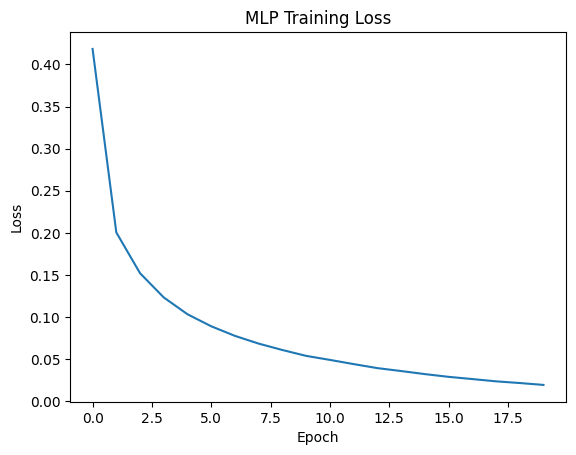

In [9]:
plt.plot(model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training Loss")
plt.show()

In [10]:
print("Test accuracy:", model.accuracy(X_test, y_test))

Test accuracy: 0.9776


## Real-time Interactive Canvas Demo

Using IPython's HTML and Google Colab's output bridge, we register a callback to pass drawings directly from a browser canvas into our trained model for instant prediction.

In [11]:
import time
from google.colab import output
from IPython.display import HTML, JSON, display

In [12]:
def recognize_drawing(pixels):
    # Convert browser data to NumPy
    start = time.perf_counter()

    x = np.asarray(
        pixels, dtype=model.dtype
    ).reshape(1, 784)

    preprocessing_ms = (time.perf_counter() - start) * 1000

    # Neural network inference
    start = time.perf_counter()

    probabilities = model.predict_proba(x)[0]

    inference_ms = (time.perf_counter() - start) * 1000

    digit = int(np.argmax(probabilities))

    return JSON({
        "digit": digit,
        "confidence": float(probabilities[digit]),
        "probabilities": probabilities.tolist(),
        "python_preprocessing_ms": preprocessing_ms,
        "inference_ms": inference_ms
    })

output.register_callback("mlp.recognize", recognize_drawing)
print("Live prediction callback ready!")

Live prediction callback ready!


In [13]:
display(HTML("""
<div id="mlp-demo" style="font-family:sans-serif;max-width:700px">
  <h3>Live MNIST Recognition</h3>
  <p>Draw a digit. Predictions update automatically.</p>

  <div style="display:flex;gap:24px;flex-wrap:wrap">

    <div>
      <b>Drawing canvas</b><br>
      <canvas id="draw"
              width="280" height="280"
              style="background:black;touch-action:none;
                     border:1px solid #888;
                     cursor:crosshair;max-width:100%">
      </canvas>
    </div>

    <div>
      <b>28×28 Model Input</b><br>
      <canvas id="preview"
              width="280" height="280"
              style="border:1px solid #888;
                     image-rendering:pixelated;
                     max-width:100%">
      </canvas>
    </div>
  </div>

  <div style="margin-top:12px">
    <button id="clear" style="padding:8px 18px">
      Clear
    </button>
    <label style="margin-left:15px">
      Brush:
      <input id="brush" type="range"
             min="5" max="40" value="20">
    </label>
  </div>

  <h2 id="prediction">Prediction: —</h2>
  <p id="confidence">Draw something to begin.</p>
  <div id="timing" style="font-size:13px;color:#888">
    Timing: —
  </div>
  <div id="scores" style="max-width:400px"></div>
</div>

<script>
(() => {
  const root = document.getElementById("mlp-demo");

  const canvas = root.querySelector("#draw");
  const ctx = canvas.getContext("2d");

  const preview = root.querySelector("#preview");
  const pctx = preview.getContext("2d");

  const prediction = root.querySelector("#prediction");
  const confidence = root.querySelector("#confidence");
  const timing = root.querySelector("#timing");
  const scores = root.querySelector("#scores");
  const brush = root.querySelector("#brush");

  // Offscreen canvas: actual 28x28 model input
  const small = document.createElement("canvas");
  small.width = 28;
  small.height = 28;
  const sctx = small.getContext("2d");

  let drawing = false;
  let timer = null;
  let busy = false;
  let dirty = false;
  let version = 0;

  const INTERVAL = 150;  // Minimum delay between predictions

  // ---------- Initialize drawing ----------

  ctx.fillStyle = "black";
  ctx.fillRect(0, 0, 280, 280);

  ctx.strokeStyle = "white";
  ctx.fillStyle = "white";
  ctx.lineCap = "round";
  ctx.lineJoin = "round";

  // ---------- Pointer position ----------

  function getPosition(e) {
    const r = canvas.getBoundingClientRect();

    return {
      x: (e.clientX - r.left) * canvas.width / r.width,
      y: (e.clientY - r.top) * canvas.height / r.height
    };
  }

  // ---------- Convert to 28x28 ----------

  function getPixels() {
    const start = performance.now();

    sctx.fillStyle = "black";
    sctx.fillRect(0, 0, 28, 28);

    sctx.imageSmoothingEnabled = true;
    sctx.imageSmoothingQuality = "high";

    sctx.drawImage(canvas, 0, 0, 28, 28);

    const data = sctx.getImageData(0, 0, 28, 28).data;
    const pixels = [];

    for (let i = 0; i < data.length; i += 4) {
      pixels.push(data[i] / 255);
    }

    const canvas_ms = performance.now() - start;

    return { pixels, canvas_ms };
  }

  // ---------- Live pixel grid ----------

  function updatePreview() {
    getPixels();

    pctx.imageSmoothingEnabled = false;
    pctx.clearRect(0, 0, 280, 280);

    pctx.drawImage(small, 0, 0, 280, 280);

    // Draw a 28x28 grid
    pctx.beginPath();
    pctx.strokeStyle = "rgba(140,140,140,0.3)";
    pctx.lineWidth = 0.5;

    for (let i = 0; i <= 28; i++) {
      const p = i * 10;
      pctx.moveTo(p, 0);
      pctx.lineTo(p, 280);
      pctx.moveTo(0, p);
      pctx.lineTo(280, p);
    }

    pctx.stroke();
  }

  // ---------- Display probabilities ----------

  function showResult(data) {
    prediction.textContent = "Prediction: " + data.digit;

    confidence.textContent =
      "Confidence: " +
      (100 * data.confidence).toFixed(1) + "%";

    scores.replaceChildren();

    data.probabilities.forEach((p, digit) => {
      const row = document.createElement("div");
      row.style.display = "flex";
      row.style.alignItems = "center";
      row.style.gap = "8px";
      row.style.marginBottom = "5px";

      const label = document.createElement("span");
      label.style.width = "15px";
      label.textContent = digit;

      const track = document.createElement("div");
      track.style.flex = "1";
      track.style.height = "12px";
      track.style.background = "#ddd";
      track.style.borderRadius = "4px";
      track.style.overflow = "hidden";

      const fill = document.createElement("div");
      fill.style.width = (p * 100) + "%";
      fill.style.height = "100%";
      fill.style.background =
        digit === data.digit ? "#16a34a" : "#64748b";

      const value = document.createElement("span");
      value.style.width = "52px";
      value.style.textAlign = "right";
      value.textContent = (p * 100).toFixed(1) + "%";

      track.appendChild(fill);
      row.append(label, track, value);
      scores.appendChild(row);
    });
  }

  // ---------- Call Python ----------

  async function predict() {
    if (busy || !dirty) return;

    dirty = false;
    busy = true;

    const requestVersion = version;
    const { pixels, canvas_ms } = getPixels();

    if (pixels.every(p => p === 0)) {
      if (requestVersion === version) {
        prediction.textContent = "Prediction: —";
        confidence.textContent = "Draw something to begin.";
        scores.replaceChildren();
      }
      busy = false;
      if (dirty) schedulePrediction();
      return;
    }

    try {
      const start = performance.now();

      const result = await google.colab.kernel.invokeFunction(
        "mlp.recognize",
        [pixels],
        {}
      );

      const roundtrip_ms = performance.now() - start;

      if (requestVersion === version) {
        const data = result.data["application/json"];

        showResult(data);

        const model_ms = data.inference_ms;
        const python_ms = data.python_preprocessing_ms;

        // Includes browser-to-Colab communication
        const total_ms = canvas_ms + roundtrip_ms;

        timing.textContent =
          "Canvas preprocessing: " + canvas_ms.toFixed(2) + " ms | " +
          "NumPy conversion: " + python_ms.toFixed(3) + " ms | " +
          "MLP inference: " + model_ms.toFixed(3) + " ms | " +
          "Total: " + total_ms.toFixed(2) + " ms";
      }

    } catch (error) {
      if (requestVersion === version) {
        prediction.textContent = "Prediction failed";
        console.error(error);
      }

    } finally {
      busy = false;
      if (dirty) schedulePrediction();
    }
  }

  // ---------- Throttle Python calls ----------

  function schedulePrediction() {
    dirty = true;

    if (timer !== null || busy) return;

    timer = setTimeout(() => {
      timer = null;
      predict();
    }, INTERVAL);
  }

  function changed() {
    version++;
    updatePreview();
    schedulePrediction();
  }

  // ---------- Drawing events ----------

  canvas.addEventListener("pointerdown", e => {
    drawing = true;
    canvas.setPointerCapture(e.pointerId);

    const p = getPosition(e);
    const radius = Number(brush.value) / 2;

    ctx.lineWidth = Number(brush.value);

    ctx.beginPath();
    ctx.arc(p.x, p.y, radius, 0, Math.PI * 2);
    ctx.fill();

    ctx.beginPath();
    ctx.moveTo(p.x, p.y);

    changed();
  });

  canvas.addEventListener("pointermove", e => {
    if (!drawing) return;

    const p = getPosition(e);

    ctx.lineWidth = Number(brush.value);
    ctx.lineTo(p.x, p.y);
    ctx.stroke();

    changed();
  });

  function stopDrawing() {
    if (!drawing) return;
    drawing = false;
    changed();
  }

  canvas.addEventListener("pointerup", stopDrawing);
  canvas.addEventListener("pointercancel", stopDrawing);

  // ---------- Clear ----------

  root.querySelector("#clear").onclick = () => {
    ctx.fillStyle = "black";
    ctx.fillRect(0, 0, 280, 280);
    ctx.fillStyle = "white";

    drawing = false;
    changed();

    prediction.textContent = "Prediction: —";
    confidence.textContent = "Draw something to begin.";
    timing.textContent = "Timing: —";
    scores.replaceChildren();
  };

  // Initial empty preview
  updatePreview();
})();
</script>
"""))

## Translation and Scale Robustness Experiment

Our MLP achieves approximately **97.76% accuracy** on the original MNIST test set. However, high test accuracy does not necessarily mean the model can recognize handwritten digits reliably when their position or size changes.

For digit recognition, moderate translation (shifting) and scaling (resizing) should generally preserve the identity of a digit.

In this experiment, we investigate two properties:

1. **Translation robustness:** How does classification accuracy change when digits are shifted horizontally or vertically?
2. **Scale robustness:** How does classification accuracy change when digits are enlarged or reduced?

In [14]:
from scipy.ndimage import affine_transform

In [15]:
def translate(X, dx=0, dy=0):
    images = np.asarray(X).reshape(-1, 28, 28)
    result = np.zeros_like(images)

    dx, dy = int(dx), int(dy)

    x0, x1 = max(0, dx), min(28, 28 + dx)
    y0, y1 = max(0, dy), min(28, 28 + dy)

    if x0 < x1 and y0 < y1:
        result[:, y0:y1, x0:x1] = images[
            :, y0-dy:y1-dy, x0-dx:x1-dx
        ]

    return result.reshape(-1, 784)


def scale(X, factor=1.0):
    if factor <= 0:
        raise ValueError("Scale factor must be positive")

    images = np.asarray(X).reshape(-1, 28, 28)

    if factor == 1.0:
        return images.copy().reshape(-1, 784)

    center = np.array([13.5, 13.5])
    matrix = np.eye(2) / factor
    offset = center - matrix @ center

    result = np.array([
        affine_transform(
            img,
            matrix,
            offset=offset,
            output_shape=(28, 28),
            order=1,
            mode="constant",
            cval=0.0,
            prefilter=False
        )
        for img in images
    ])

    return result.reshape(-1, 784)

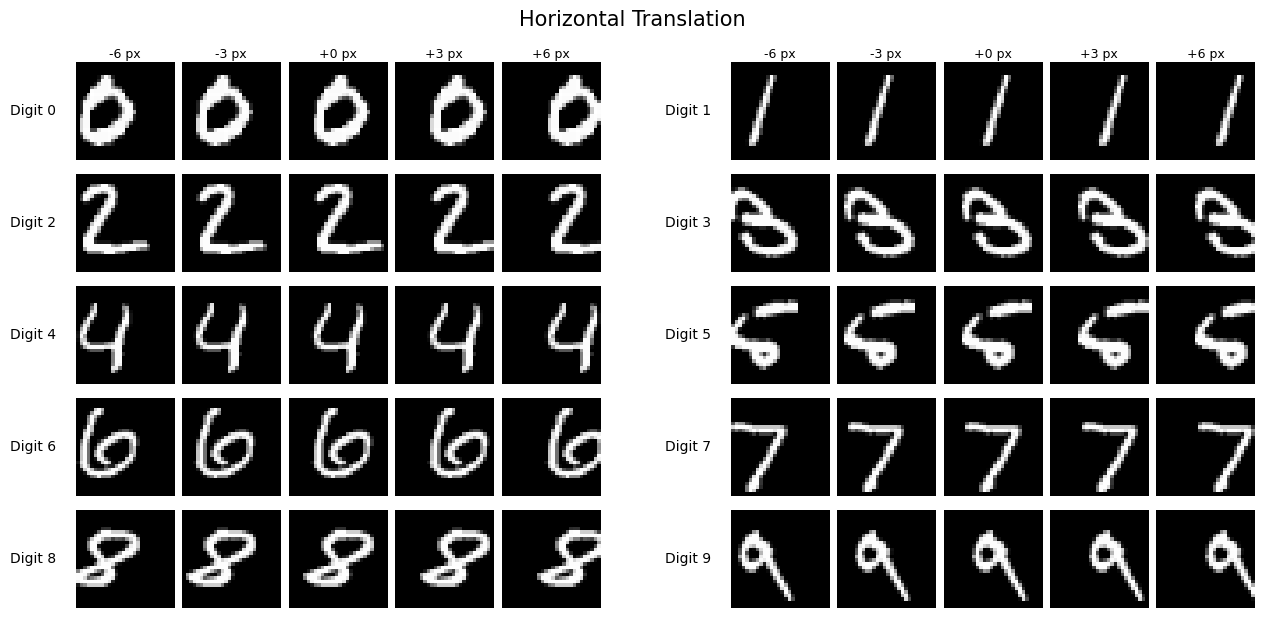

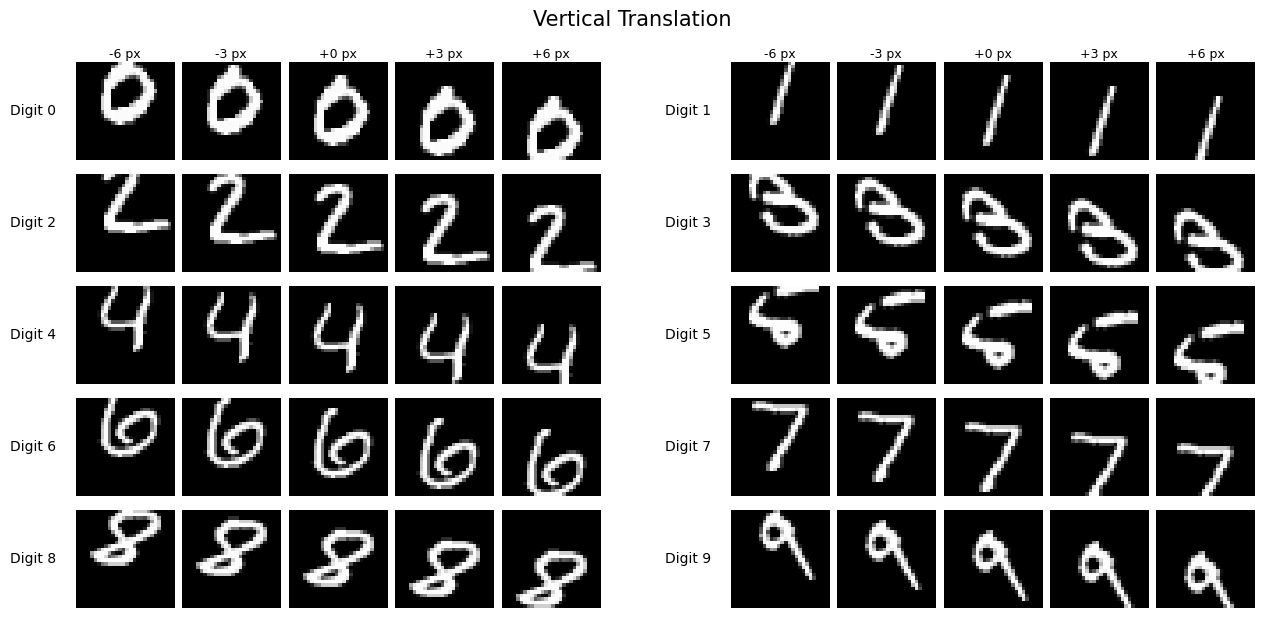

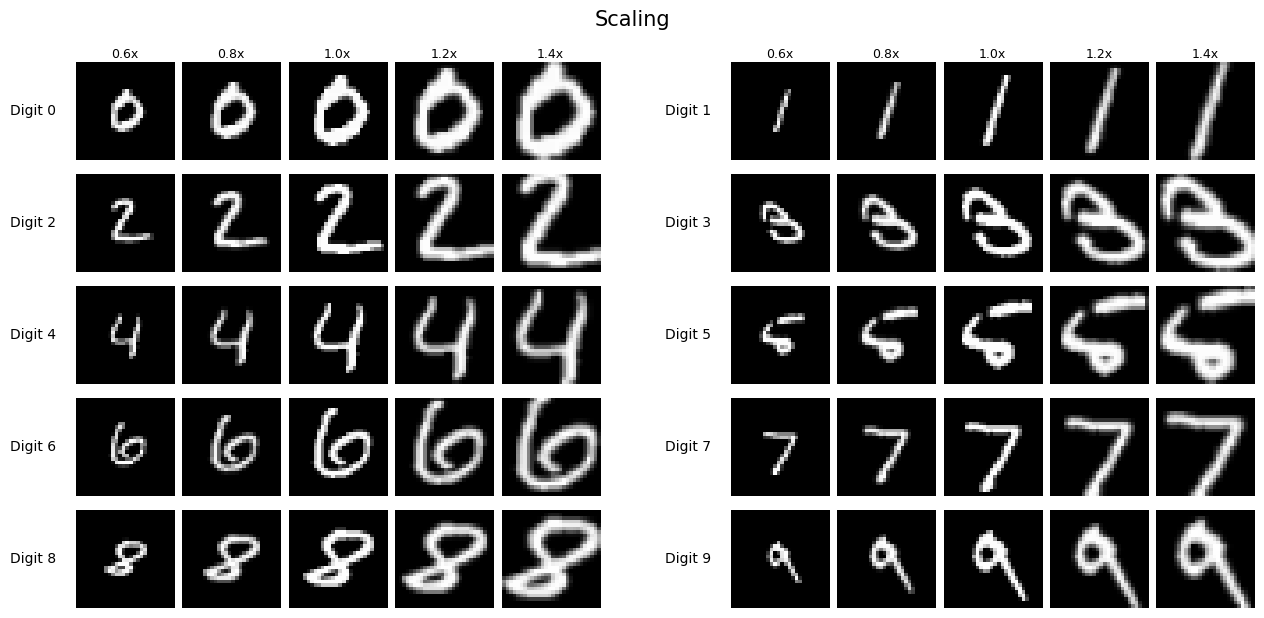

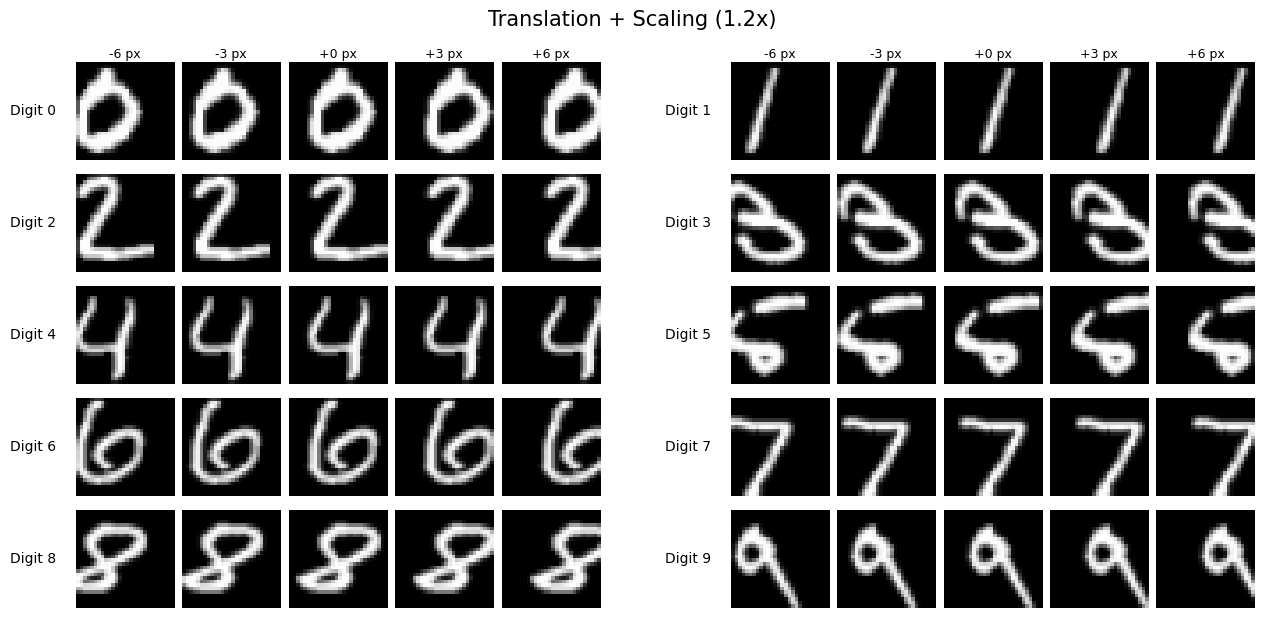

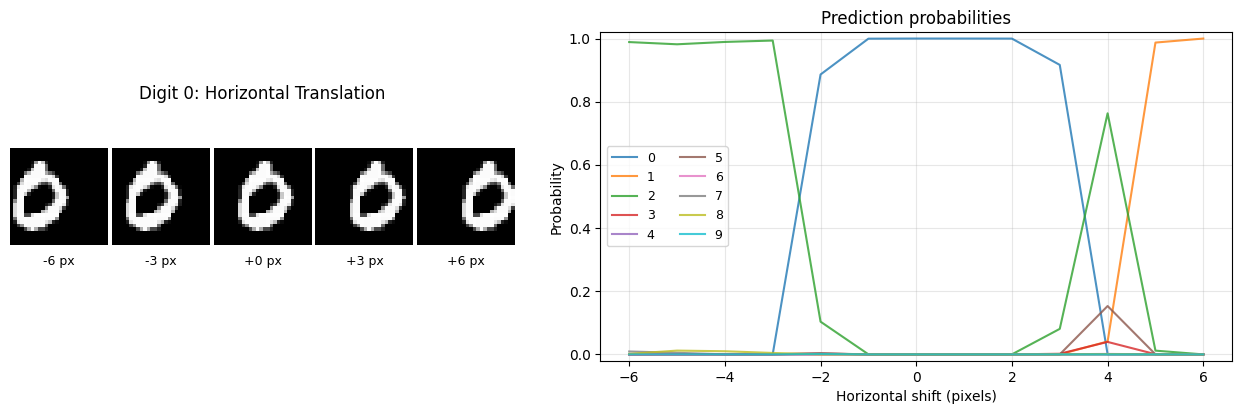

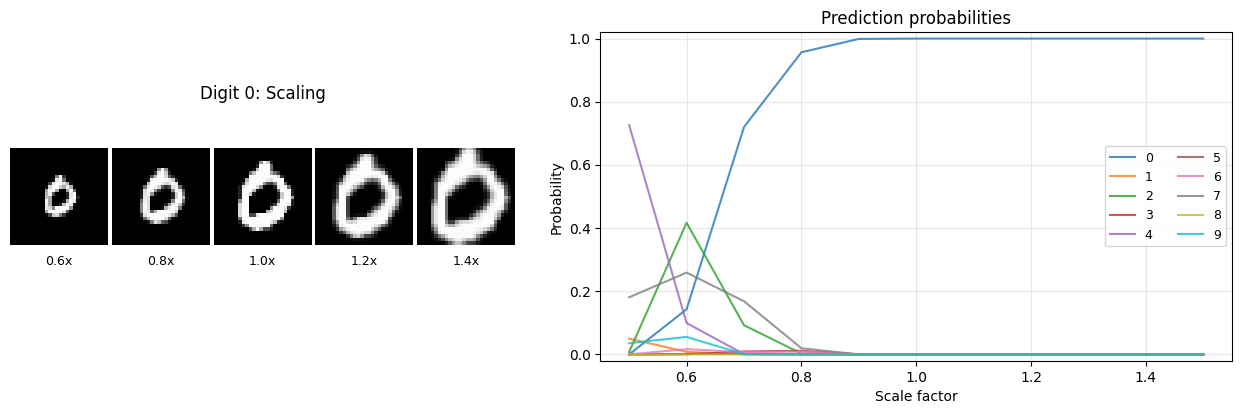

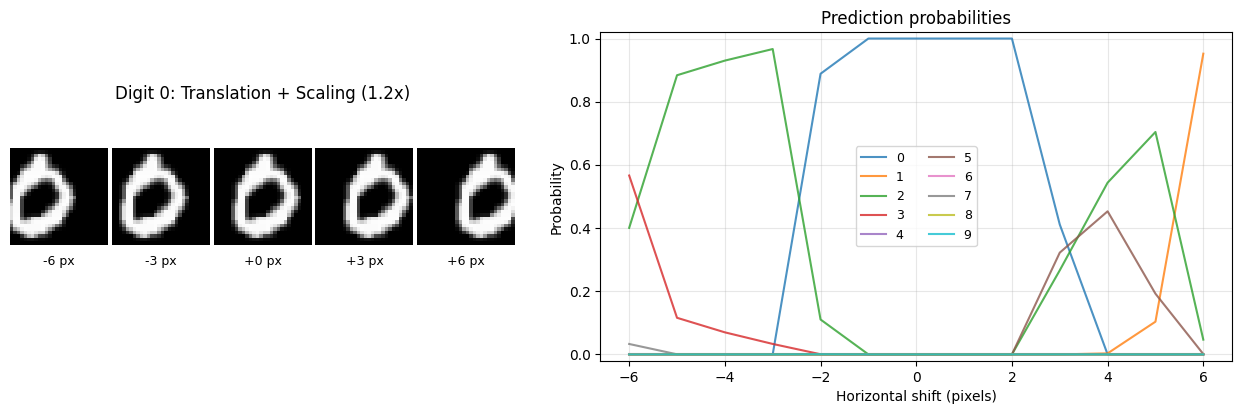

In [16]:

# ==========================================
# 1. Visualization settings
# ==========================================

EXAMPLE_DIGIT = 0

visual_shifts = [-6, -3, 0, 3, 6]
visual_scales = [0.6, 0.8, 1.0, 1.2, 1.4]
combined_factor = 1.2

# Finer resolution for probability curves
prob_shifts = np.arange(-6, 7)
prob_scales = np.round(np.arange(0.5, 1.51, 0.1), 2)

# Select the first test sample of each digit
labels = np.asarray(y_test)
labels = (
    np.argmax(labels, axis=1)
    if labels.ndim == 2
    else labels.reshape(-1)
)

sample_indices = [
    np.flatnonzero(labels == digit)[0]
    for digit in range(10)
]

X_samples = X_test[sample_indices]


# ==========================================
# 2. Shared image display function
# ==========================================

def draw_digit(ax, image):
    ax.imshow(
        image.reshape(28, 28),
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    ax.set_axis_off()


# ==========================================
# 3. Transformation grids: digits 0–9
# ==========================================

def show_digit_grid(title, values, transform_fn, label_fn):
    fig = plt.figure(figsize=(13, 6.5))

    # Two groups of five images per row.
    # The space between groups accommodates digit labels.
    outer = fig.add_gridspec(
        5, 2,
        left=0.07,
        right=0.98,
        top=0.90,
        bottom=0.06,
        wspace=0.24,
        hspace=0.14
    )

    for digit in range(10):
        row = digit // 2
        group = digit % 2

        inner = outer[row, group].subgridspec(
            1, 5,
            wspace=0.04
        )

        image = X_samples[digit:digit + 1]
        transformed = [
            transform_fn(image, value)[0]
            for value in values
        ]

        for j, value in enumerate(values):
            ax = fig.add_subplot(inner[0, j])
            draw_digit(ax, transformed[j])

            # Show column labels only on the first row
            if row == 0:
                ax.set_title(
                    label_fn(value),
                    fontsize=9,
                    pad=3
                )

            # Add the digit label on the left of each group
            if j == 0:
                ax.text(
                    -0.20, 0.5,
                    f"Digit {digit}",
                    transform=ax.transAxes,
                    fontsize=10,
                    ha="right",
                    va="center",
                    clip_on=False
                )

    fig.suptitle(title, fontsize=15)
    plt.show()


# ==========================================
# 4. Display each transformation
# ==========================================

# Horizontal translation
show_digit_grid(
    "Horizontal Translation",
    visual_shifts,
    lambda X, dx: translate(X, dx=dx),
    lambda dx: f"{dx:+d} px"
)

# Vertical translation
show_digit_grid(
    "Vertical Translation",
    visual_shifts,
    lambda X, dy: translate(X, dy=dy),
    lambda dy: f"{dy:+d} px"
)

# Scaling
show_digit_grid(
    "Scaling",
    visual_scales,
    lambda X, s: scale(X, s),
    lambda s: f"{s:.1f}x"
)

# Translation + scaling
show_digit_grid(
    f"Translation + Scaling ({combined_factor:.1f}x)",
    visual_shifts,
    lambda X, dx: translate(
        scale(X, combined_factor),
        dx=dx
    ),
    lambda dx: f"{dx:+d} px"
)


# ==========================================
# 5. Calculate prediction probabilities
# ==========================================

X_digit = X_samples[
    EXAMPLE_DIGIT:EXAMPLE_DIGIT + 1
]

def get_probabilities(images):
    return model.predict_proba(
        images.reshape(-1, 784)
    )


# Translation only
translated = np.concatenate([
    translate(X_digit, dx=int(dx))
    for dx in prob_shifts
])

probs_translate = get_probabilities(translated)


# Scaling only
scaled = np.concatenate([
    scale(X_digit, factor=float(s))
    for s in prob_scales
])

probs_scale = get_probabilities(scaled)


# Translation + scaling
combined = np.concatenate([
    translate(
        scale(X_digit, combined_factor),
        dx=int(dx)
    )
    for dx in prob_shifts
])

probs_combined = get_probabilities(combined)


# ==========================================
# 6. Images and probability graph side by side
# ==========================================

def plot_probabilities_with_images(
    title,
    x_values,
    probabilities,
    visual_values,
    transform_fn,
    xlabel,
    label_fn
):
    fig = plt.figure(figsize=(13, 4.5))

    outer = fig.add_gridspec(
        1, 2,
        width_ratios=[1, 1.25],
        left=0.04,
        right=0.98,
        top=0.88,
        bottom=0.15,
        wspace=0.15
    )

    # LEFT: transformed digit images
    inner = outer[0, 0].subgridspec(
        1, 5,
        wspace=0.04
    )

    for j, value in enumerate(visual_values):
        ax = fig.add_subplot(inner[0, j])

        transformed = transform_fn(X_digit, value)
        draw_digit(ax, transformed[0])

        ax.text(
            0.5, -0.10,
            label_fn(value),
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=9
        )

        if j == 2:
            ax.set_title(
                f"Digit {EXAMPLE_DIGIT}: {title}",
                fontsize=12,
                pad=35
            )

    # RIGHT: prediction probability graph
    ax = fig.add_subplot(outer[0, 1])

    for digit in range(10):
        ax.plot(
            x_values,
            probabilities[:, digit],
            label=str(digit),
            alpha=0.8
        )

    ax.set_title("Prediction probabilities", fontsize=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Probability")
    ax.set_ylim(-0.02, 1.02)
    ax.legend(ncol=2, fontsize=9)
    ax.grid(alpha=0.3)

    plt.show()


# ==========================================
# 7. Three individual prediction experiments
# ==========================================

# Horizontal translation
plot_probabilities_with_images(
    title="Horizontal Translation",
    x_values=prob_shifts,
    probabilities=probs_translate,
    visual_values=visual_shifts,
    transform_fn=lambda X, dx: translate(X, dx=dx),
    xlabel="Horizontal shift (pixels)",
    label_fn=lambda dx: f"{dx:+d} px"
)

# Scaling
plot_probabilities_with_images(
    title="Scaling",
    x_values=prob_scales,
    probabilities=probs_scale,
    visual_values=visual_scales,
    transform_fn=lambda X, s: scale(X, s),
    xlabel="Scale factor",
    label_fn=lambda s: f"{s:.1f}x"
)

# Translation + scaling
plot_probabilities_with_images(
    title=f"Translation + Scaling ({combined_factor:.1f}x)",
    x_values=prob_shifts,
    probabilities=probs_combined,
    visual_values=visual_shifts,
    transform_fn=lambda X, dx: translate(
        scale(X, combined_factor),
        dx=dx
    ),
    xlabel="Horizontal shift (pixels)",
    label_fn=lambda dx: f"{dx:+d} px"
)


Original MNIST accuracy: 97.76%

Translation only:
 Shift   Horizontal     Vertical
    -6       20.78%       11.90%
    -5       27.50%       15.17%
    -4       40.59%       28.34%
    -3       57.36%       52.80%
    -2       79.49%       79.87%
    -1       95.59%       94.57%
     0       97.76%       97.76%
     1       95.74%       95.62%
     2       83.55%       81.61%
     3       56.31%       54.16%
     4       33.51%       27.01%
     5       19.92%       12.61%
     6       10.74%        7.28%

Scaling only:
  Scale     Accuracy   Change (pp)
  0.50x       28.31%       -69.45
  0.60x       46.11%       -51.65
  0.70x       65.78%       -31.98
  0.80x       87.21%       -10.55
  0.90x       96.10%        -1.66
  1.00x       97.76%        +0.00
  1.10x       96.47%        -1.29
  1.20x       91.52%        -6.24
  1.30x       81.95%       -15.81
  1.40x       70.91%       -26.85
  1.50x       58.26%       -39.50

Translation + Scaling:
 Shift       0.8x       1.0x       1.2x

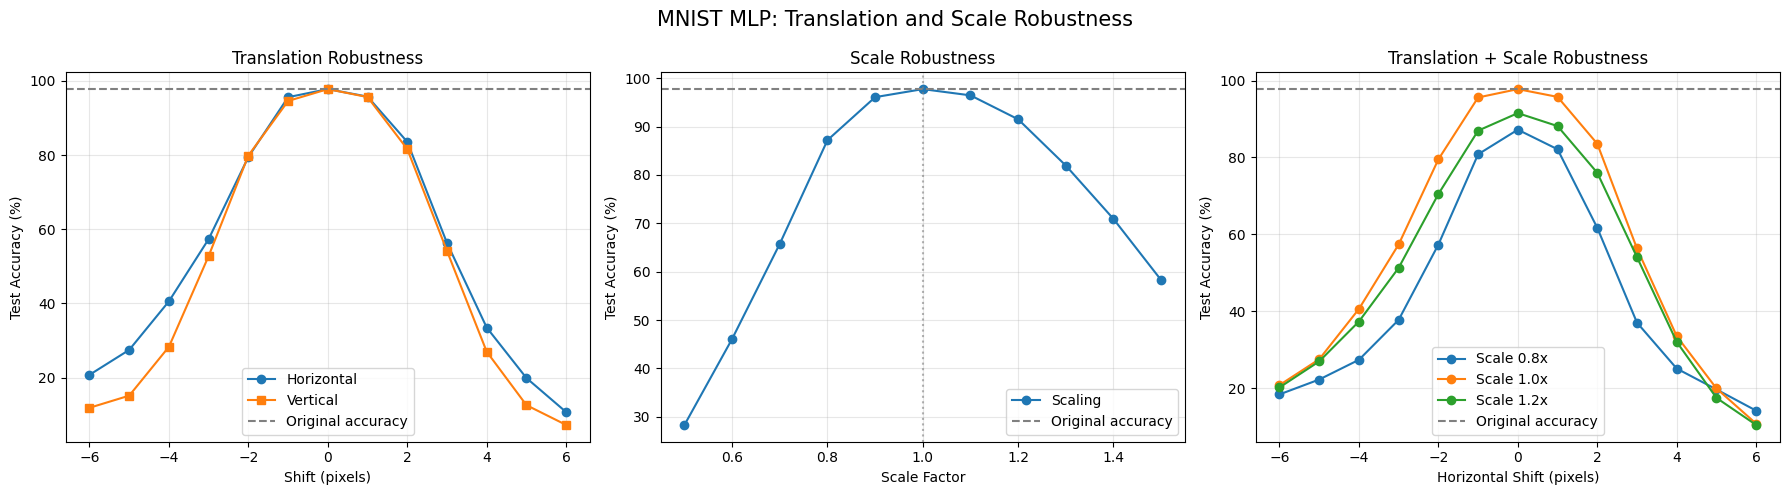

In [17]:

# ==========================================
# 1. Experiment settings
# ==========================================

shifts = np.arange(-6, 7, 1)
scales = np.round(np.arange(0.5, 1.51, 0.1), 2)
combined_scales = [0.8, 1.0, 1.2]

baseline = model.accuracy(X_test, y_test) * 100

print(
    f"Original MNIST accuracy: {baseline:.2f}%",
    flush=True
)


# ==========================================
# 2. Translation-only experiment
# ==========================================

acc_horizontal = []
acc_vertical = []

print("\nTranslation only:", flush=True)
print(
    f"{'Shift':>6} {'Horizontal':>12} {'Vertical':>12}",
    flush=True
)

for shift in shifts:
    h = model.accuracy(
        translate(X_test, dx=shift),
        y_test
    ) * 100

    v = model.accuracy(
        translate(X_test, dy=shift),
        y_test
    ) * 100

    acc_horizontal.append(h)
    acc_vertical.append(v)

    print(
        f"{shift:>6} {h:>11.2f}% {v:>11.2f}%",
        flush=True
    )


# ==========================================
# 3. Scaling-only experiment
# ==========================================

acc_scaling = []

print("\nScaling only:", flush=True)
print(
    f"{'Scale':>7} {'Accuracy':>12} {'Change (pp)':>13}",
    flush=True
)

for factor in scales:
    acc = model.accuracy(
        scale(X_test, factor),
        y_test
    ) * 100

    acc_scaling.append(acc)

    print(
        f"{factor:>6.2f}x {acc:>11.2f}% "
        f"{acc-baseline:>+12.2f}",
        flush=True
    )


# ==========================================
# 4. Translation + scaling experiment
# ==========================================

acc_combined = {
    factor: [] for factor in combined_scales
}

print("\nTranslation + Scaling:", flush=True)
print(
    f"{'Shift':>6}" +
    "".join(
        f" {factor:>9.1f}x"
        for factor in combined_scales
    ),
    flush=True
)

# Avoid scaling the test set repeatedly
scaled_sets = {
    factor: scale(X_test, factor)
    for factor in combined_scales
}

for shift in shifts:
    row = []

    for factor in combined_scales:
        acc = model.accuracy(
            translate(
                scaled_sets[factor],
                dx=shift
            ),
            y_test
        ) * 100

        acc_combined[factor].append(acc)
        row.append(acc)

    print(
        f"{shift:>6}" +
        "".join(
            f" {acc:>9.2f}%"
            for acc in row
        ),
        flush=True
    )

print("\nAll tests completed!", flush=True)


# ==========================================
# 5. Accuracy line charts
# ==========================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

# ------------------------------------------
# Chart 1: Translation robustness
# ------------------------------------------

axes[0].plot(
    shifts,
    acc_horizontal,
    "o-",
    label="Horizontal"
)

axes[0].plot(
    shifts,
    acc_vertical,
    "s-",
    label="Vertical"
)

axes[0].axhline(
    baseline,
    color="gray",
    linestyle="--",
    label="Original accuracy"
)

axes[0].set_title("Translation Robustness")
axes[0].set_xlabel("Shift (pixels)")
axes[0].set_ylabel("Test Accuracy (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)


# ------------------------------------------
# Chart 2: Scaling robustness
# ------------------------------------------

axes[1].plot(
    scales,
    acc_scaling,
    "o-",
    label="Scaling"
)

axes[1].axhline(
    baseline,
    color="gray",
    linestyle="--",
    label="Original accuracy"
)

axes[1].axvline(
    1.0,
    color="gray",
    linestyle=":",
    alpha=0.6
)

axes[1].set_title("Scale Robustness")
axes[1].set_xlabel("Scale Factor")
axes[1].set_ylabel("Test Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)


# ------------------------------------------
# Chart 3: Translation + scaling robustness
# ------------------------------------------

for factor, accuracies in acc_combined.items():
    axes[2].plot(
        shifts,
        accuracies,
        "o-",
        label=f"Scale {factor:.1f}x"
    )

axes[2].axhline(
    baseline,
    color="gray",
    linestyle="--",
    label="Original accuracy"
)

axes[2].set_title("Translation + Scale Robustness")
axes[2].set_xlabel("Horizontal Shift (pixels)")
axes[2].set_ylabel("Test Accuracy (%)")
axes[2].legend()
axes[2].grid(alpha=0.3)


# ------------------------------------------
# Display all three plots
# ------------------------------------------

plt.suptitle(
    "MNIST MLP: Translation and Scale Robustness",
    fontsize=15
)

plt.tight_layout()
plt.show()


## Feature Visualization — Activation Maximization

We want to generate an input image that maximizes the activation of a chosen output neuron in our trained MLP.

For MNIST, each output neuron corresponds to a digit $j \in \{0,1,\ldots,9\}$.

### 1. Optimization Objective

Following the original feature visualization formulation:

$$
\boxed{
\mathbf{x}^* =
\arg\max_{\mathbf{x}}
\left[z_j(\mathbf{x})+\lambda R(\mathbf{x})\right]
}
$$

where:

- $\mathbf{x}\in[0,1]^{784}$ is the input image.
- $z_j(\mathbf{x})$ is the pre-softmax logit for digit $j$.
- $R(\mathbf{x})$ is a regularization function.
- $\lambda\geq 0$ controls regularization strength.

### 2. L2 Regularization

We use the negative squared L2 norm:

$$
R(\mathbf{x})=-\|\mathbf{x}\|_2^2
=-\sum_{i=1}^{784}x_i^2
$$

Thus, the optimization objective becomes:

$$
\boxed{
\mathbf{x}^* =
\arg\max_{\mathbf{x}}
\left[
z_j(\mathbf{x})-\lambda\|\mathbf{x}\|_2^2
\right]
}
$$

The L2 penalty discourages excessively large pixel values.

### 3. Gradient Ascent

We optimize the input pixels while keeping all network weights fixed.

The update rule is:

$$
\boxed{
\mathbf{x}^{(k+1)}
=
\operatorname{clip}_{[0,1]}
\left[
\mathbf{x}^{(k)}
+\eta
\left(
\nabla_{\mathbf{x}}z_j(\mathbf{x}^{(k)})
-2\lambda\mathbf{x}^{(k)}
\right)
\right]
}
$$

where $\eta$ is the learning rate.

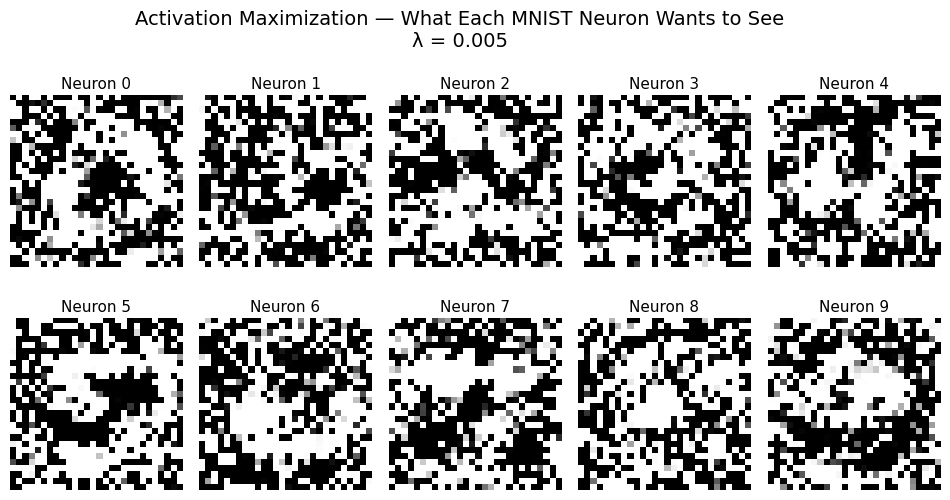

In [18]:

# ============================================================
# Activation Maximization
#
# J(x) = z_j(x) + lambda * R(x)
# R(x) = -||x||^2
#
# Therefore:
# J(x) = z_j(x) - lambda * ||x||^2
# ============================================================

STEPS = 180
LR = 0.08
SEED = 42
LAMBDA = 0.005


def digit_input_gradient(model, x, digit):
    """Compute target logit and its gradient w.r.t. input."""

    a = np.asarray(x, dtype=model.dtype).reshape(1, 784)
    activations = [a]

    # Forward pass
    for layer in model.layers:

        if isinstance(layer, Linear):
            a = a @ layer.W.T + layer.b.T

        elif isinstance(layer, ReLU):
            a = np.maximum(a, 0)

        activations.append(a)

    logit = float(a[0, digit])

    # Backpropagate target logit to the input
    grad = np.zeros_like(a)
    grad[0, digit] = 1.0

    for i in range(len(model.layers) - 1, -1, -1):

        layer = model.layers[i]

        if isinstance(layer, Linear):
            grad = grad @ layer.W

        elif isinstance(layer, ReLU):
            grad = grad * (activations[i] > 0)

    return logit, grad.reshape(28, 28)


def maximize_digit(model, digit, lambda_reg=LAMBDA,
                   steps=STEPS, lr=LR, seed=SEED,
                   checkpoints=None):
    """Optimize input pixels while keeping model weights fixed."""

    rng = np.random.default_rng(seed)

    x = rng.uniform(
        0.1, 0.3, (28, 28)
    ).astype(model.dtype)

    checkpoints = set(checkpoints or [])

    snapshots = {}
    logits = []
    objectives = []

    for step in range(steps + 1):

        logit, grad = digit_input_gradient(
            model, x, digit
        )

        objective = logit - lambda_reg * np.sum(x**2)

        logits.append(logit)
        objectives.append(objective)

        if step in checkpoints:
            snapshots[step] = x.copy()

        if step == steps:
            break

        # Gradient of J(x)
        grad = grad - 2 * lambda_reg * x

        # Normalize gradient
        grad = grad / (
            np.sqrt(np.mean(grad**2)) + 1e-8
        )

        # Gradient ascent with pixel clipping
        x = np.clip(
            x + lr * grad, 0, 1
        )

    return (
        x,
        snapshots,
        np.array(logits),
        np.array(objectives)
    )


# ============================================================
# Visualize all 10 digit neurons — Compact Layout
# ============================================================

fig, axes = plt.subplots(
    2, 5,
    figsize=(12, 5.2)
)

for digit, ax in enumerate(axes.flat):

    image, _, _, _ = maximize_digit(
        model, digit, lambda_reg=LAMBDA
    )

    ax.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(
        f"Neuron {digit}",
        fontsize=11,
        pad=5
    )

    ax.axis("off")

fig.suptitle(
    "Activation Maximization — What Each MNIST Neuron Wants to See\n"
    f"λ = {LAMBDA}",
    fontsize=14,
    y=0.99
)

fig.subplots_adjust(
    hspace=0.12,
    wspace=0.10,
    top=0.85,
    bottom=0.04
)

plt.show()


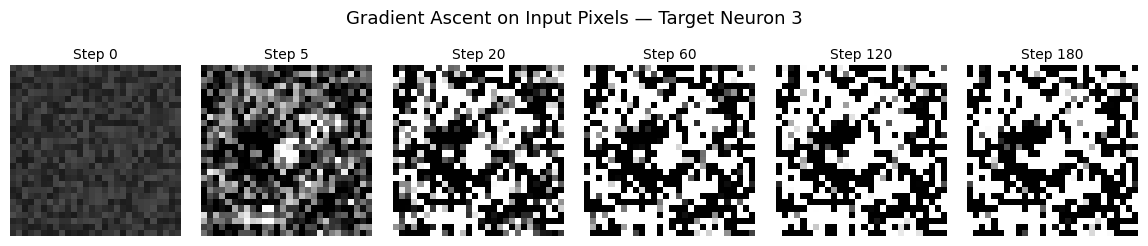

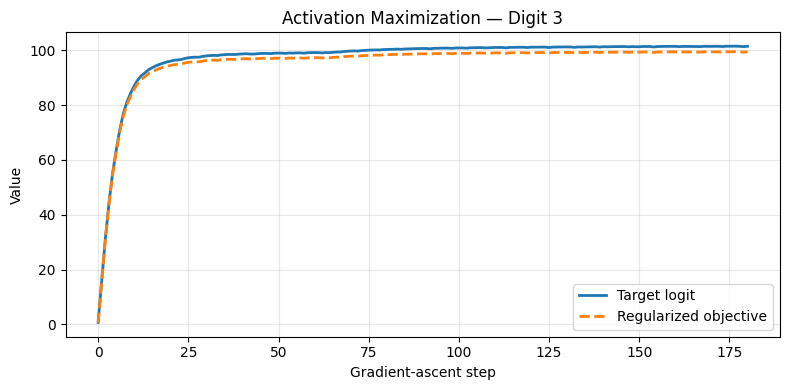

In [19]:

# ============================================================
# Gradient Ascent Evolution — Target Neuron 3
# ============================================================

TARGET_DIGIT = 3

CHECKPOINTS = [0, 5, 20, 60, 120, 180]

image, snapshots, logits, objectives = maximize_digit(
    model,
    TARGET_DIGIT,
    lambda_reg=LAMBDA,
    checkpoints=CHECKPOINTS
)


# ============================================================
# Figure 1: Optimization Steps — Compact Layout
# ============================================================

fig, axes = plt.subplots(
    1, len(CHECKPOINTS),
    figsize=(12, 2.5)
)

for ax, step in zip(axes, CHECKPOINTS):

    ax.imshow(
        snapshots[step],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(
        f"Step {step}",
        fontsize=10,
        pad=5
    )

    ax.axis("off")

fig.suptitle(
    f"Gradient Ascent on Input Pixels — Target Neuron {TARGET_DIGIT}",
    fontsize=13,
    y=0.98
)

fig.subplots_adjust(
    left=0.03,
    right=0.97,
    bottom=0.05,
    top=0.78,
    wspace=0.12
)

plt.show()


# ============================================================
# Figure 2: Optimization Curve
# ============================================================

plt.figure(figsize=(8, 4))

plt.plot(
    logits,
    label="Target logit",
    linewidth=2
)

plt.plot(
    objectives,
    "--",
    label="Regularized objective",
    linewidth=2
)

plt.xlabel("Gradient-ascent step")
plt.ylabel("Value")

plt.title(
    f"Activation Maximization — Digit {TARGET_DIGIT}"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


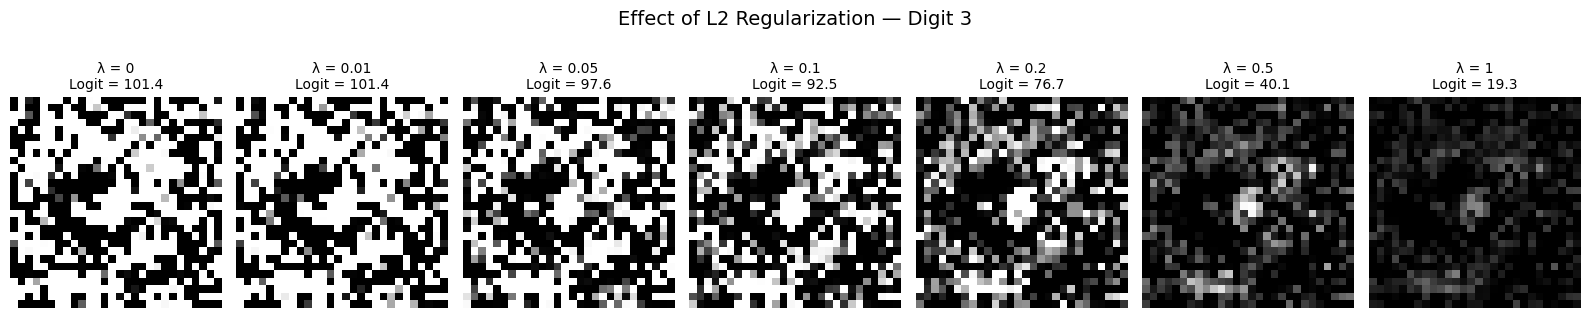

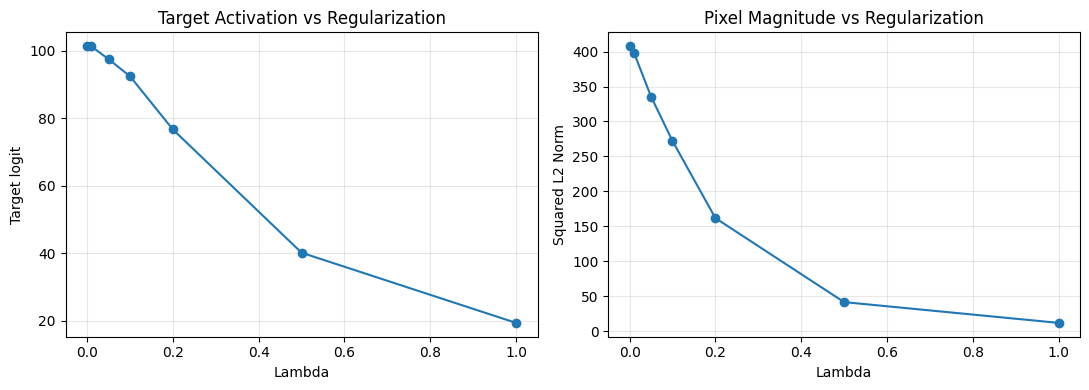

Regularization Comparison — Digit 3
------------------------------------------------
    Lambda        Logit      L2 Squared
     0.000      101.427         407.834
     0.010      101.369         398.757
     0.050       97.575         335.649
     0.100       92.492         272.115
     0.200       76.701         161.677
     0.500       40.132          41.372
     1.000       19.308          11.618


In [20]:

# ============================================================
# Effect of L2 Regularization
# ============================================================

LAMBDA_VALUES = [0, 0.01, 0.05, 0.1, 0.2, 0.5, 1.0]

images = []
final_logits = []
l2_norms = []

for lam in LAMBDA_VALUES:

    image, _, logits, _ = maximize_digit(
        model,
        TARGET_DIGIT,
        lambda_reg=lam,
        seed=SEED
    )

    images.append(image)
    final_logits.append(logits[-1])
    l2_norms.append(np.sum(image**2))


# ------------------------------------------------------------
# Figure 1: Visual comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, len(LAMBDA_VALUES),
    figsize=(16, 3.2)
)

for ax, lam, image, logit in zip(
    axes, LAMBDA_VALUES, images, final_logits
):

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)

    ax.set_title(
        f"λ = {lam:g}\nLogit = {logit:.1f}",
        fontsize=10
    )

    ax.axis("off")

fig.suptitle(
    f"Effect of L2 Regularization — Digit {TARGET_DIGIT}",
    fontsize=14,
    y=1.05
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Figure 2: Quantitative comparison
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(LAMBDA_VALUES, final_logits, "o-")
axes[0].set(
    title="Target Activation vs Regularization",
    xlabel="Lambda",
    ylabel="Target logit"
)
axes[0].grid(alpha=0.3)

axes[1].plot(LAMBDA_VALUES, l2_norms, "o-")
axes[1].set(
    title="Pixel Magnitude vs Regularization",
    xlabel="Lambda",
    ylabel="Squared L2 Norm"
)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Print numerical results
# ------------------------------------------------------------

print(f"Regularization Comparison — Digit {TARGET_DIGIT}")
print("-" * 48)
print(f"{'Lambda':>10} {'Logit':>12} {'L2 Squared':>15}")

for lam, logit, l2 in zip(
    LAMBDA_VALUES, final_logits, l2_norms
):
    print(f"{lam:10.3f} {logit:12.3f} {l2:15.3f}")
